# 03 — Baselines

How well can each protein (CLR) be predicted, and how much of that comes from cell-type identity?

| # | Model | Input |
|---|---|---|
| 0 | Global mean | nothing (constant per protein) |
| 1 | Cell-type mean | **the annotated cell-type label** (not RNA) |
| 2 | Own gene | RNA of the protein's mapped gene(s): `y = a + b·x` per protein |
| 3a | Ridge on PCA | PCA of 2,000 HVGs |
| 3b | Ridge on HVG | 2,000 z-scored HVGs |

**Rules**
* Random cell-level split 70/15/15, stratified by cell type, saved once to `results/splits/random_split.csv.gz`.
* Everything learned from data (means, slopes, HVG selection, scaling, PCA, ridge weights) is fit on
  **training cells only**.
* Hyperparameters are chosen on validation. The selection metric, fixed beforehand, is the mean
  validation Pearson (all cells) over all 134 proteins.
* Ridge grids: PCA components {50, 100, 200, 400, 800, full rank = 2,000}. If the best setting lies on
  a grid edge, the grid is **extended based on validation** and every extension is logged. Full rank is
  an upper bound by construction.
* Sanity check: ridge on full-rank PCA must equal ridge on the same (unscaled, centered) HVG matrix,
  because ridge is invariant to orthogonal rotations of its inputs.
* Within-type metric threshold, fixed now for every split: a cell type is evaluated if it has >= 50
  cells in the evaluated part (random split: validation and test; donor split in Phase 5: test).
* **Test cells are not evaluated in this notebook.** They are used once, after all models (including
  Phase 4) are frozen.
* Headline metrics use the 110-protein **primary** set. Secondary (7) and unavailable (17) proteins are
  reported separately.
* Undefined correlations stay NaN and are never counted as 0: the global mean has no Pearson at all,
  and the cell-type mean has no within-type Pearson.
* Validation numbers for ridge are slightly optimistic, because its hyperparameters were picked on
  the same cells. The test set will give an unbiased number.

In [1]:
import os, sys, time, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import h5py
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from citeseq.paths import CITE_H5AD, REPO_ROOT, RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR
from citeseq.io import load_cite, _read_dataframe
from citeseq.correlation import load_protein_gene_map, mapped_log_expression, pearson_columns
from citeseq.splits import make_random_split, save_split, load_split
from citeseq.baselines import GlobalMean, CellTypeMean, OwnGeneLinear, RidgePath, HVGPCAFeatures
from citeseq.metrics import evaluate, headline
from citeseq import plotting as P

SEED = 0
N_HVG = 2000
PCS_GRID = [50, 100, 200, 400, 800, N_HVG]          # N_HVG = full rank
MIN_CELLS_WITHIN = {"random_split": {"val": 50, "test": 50}, "donor_split_phase5": {"test": 50}}
MIN_CELLS = MIN_CELLS_WITHIN["random_split"]["val"]
MAX_EXPANSIONS = 5
ALPHA_PCA = [float(a) for a in np.logspace(-2, 4, 13)]
ALPHA_HVG = [float(a) for a in np.logspace(0, 5, 11)]
SUBSET = int(os.environ.get("CITESEQ_SUBSET", 0)) or None
OUT_FIG = FIGURES_DIR if SUBSET is None else PROCESSED_DIR / "test_figures"
OUT_FIG.mkdir(parents=True, exist_ok=True)
SPLIT_PATH = RESULTS_DIR / "splits/random_split.csv.gz" if SUBSET is None else PROCESSED_DIR / "test_split.csv.gz"
P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)
print("subset:", SUBSET)

subset: None


## 1. Load data and the split

In [2]:
with h5py.File(CITE_H5AD) as f:
    var = _read_dataframe(f["var"])
mask = None
if SUBSET:
    mask = np.zeros(90_261, bool)
    mask[np.random.default_rng(SEED).choice(mask.size, SUBSET, replace=False)] = True
rna = load_cite(CITE_H5AD, "layers/counts", cell_mask=mask, var_mask=(var["feature_types"] == "GEX").to_numpy())
adt = load_cite(CITE_H5AD, "X", cell_mask=mask, var_mask=(var["feature_types"] == "ADT").to_numpy())
proteins = list(adt.var_names)
pmap = load_protein_gene_map(REPO_ROOT / "resources/protein_gene_map.csv", rna.var_names).set_index("protein").loc[proteins]
SETS = pmap["analysis_set"]
primary = SETS.index[SETS == "primary"].tolist()
print(rna.shape, adt.shape, SETS.value_counts().to_dict())

if SPLIT_PATH.exists() and SUBSET is None:
    split = load_split(SPLIT_PATH, rna.obs_names)
    print("loaded existing split:", SPLIT_PATH.name)
else:
    split = make_random_split(rna.obs, seed=SEED)
    save_split(split, SPLIT_PATH)
    print("created and saved split:", SPLIT_PATH)
print(split.value_counts().to_string())
print("min cells of a cell type per part:", pd.crosstab(rna.obs["cell_type"], split).min().to_dict())

(90261, 13953) (90261, 134) {'primary': 110, 'unavailable': 17, 'secondary': 7}
loaded existing split: random_split.csv.gz
split
train    63182
test     13540
val      13539
min cells of a cell type per part: {'test': 2, 'train': 13, 'val': 3}


## 2. Inputs

* Own-gene RNA: summed raw counts of the mapped gene(s) -> log1p CP10k (NaN column for proteins without
  a measured gene).
* All genes: log1p CP10k. This is per cell, so no information is shared between cells.
* Only training and validation cells are taken out; **test cells are never indexed below.**

In [3]:
total = np.asarray(rna.X.sum(axis=1)).ravel()
usable = pmap["usable"].to_numpy()
R = np.full((rna.n_obs, len(proteins)), np.nan, dtype=np.float32)
R[:, usable] = mapped_log_expression(rna.X, rna.var_names, total, pmap.loc[usable, "gene_list"].tolist())
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)

cell_type_all = rna.obs["cell_type"].astype(str).to_numpy()
tr = (split == "train").to_numpy()
va = (split == "val").to_numpy()
print(f"train {tr.sum():,} | val {va.sum():,} | test {(split == 'test').sum():,} (not used here)")
X_tr, X_va = rna.X[tr], rna.X[va]
obs_tr = rna.obs.loc[tr]
ct_tr = rna.obs["cell_type"].astype(str).to_numpy()[tr]
ct_va = rna.obs["cell_type"].astype(str).to_numpy()[va]
Y_all = adt.X.toarray()
Y_tr, Y_va = Y_all[tr], Y_all[va]
R_tr, R_va = R[tr], R[va]
gene_names = np.asarray(rna.var_names)
del rna, adt, Y_all, R

train 63,182 | val 13,539 | test 13,540 (not used here)


## 3. Train-only features: HVG, scaling, PCA

In [4]:
t0 = time.time()
feats = HVGPCAFeatures(n_top_genes=N_HVG, max_pcs=None, seed=SEED).fit(X_tr, obs_tr, gene_names)
Z_tr, Z_va = feats.transform_pca(X_tr, N_HVG), feats.transform_pca(X_va, N_HVG)
H_tr, H_va = feats.transform_hvg(X_tr), feats.transform_hvg(X_va)
print(f"features in {time.time() - t0:.0f}s | HVGs: {feats.hvg_mask_.sum()} | "
      f"PCA components: {feats.pca_.n_components_}; variance explained by 200 PCs: "
      f"{feats.pca_.explained_variance_ratio_[:200].sum():.3f}")
own_genes_in_hvg = pmap.loc[usable, "gene_list"].explode().isin(feats.hvg_names_).mean()
print(f"share of mapped genes that are among the HVGs: {own_genes_in_hvg:.1%}")

features in 21s | HVGs: 2000 | PCA components: 2000; variance explained by 200 PCs: 0.637
share of mapped genes that are among the HVGs: 68.0%


## Within-type threshold: how many cell types can be evaluated?

Only cell-type **counts** of each part are used here (no protein values), so looking at the test part
does not leak information about results.

In [5]:
counts = pd.crosstab(pd.Series(cell_type_all, name="cell_type"), pd.Series(split.to_numpy(), name="part"))
evaluable = {part: int((counts[part] >= MIN_CELLS_WITHIN["random_split"].get(part, MIN_CELLS)).sum())
             for part in ["val", "test"]}
print("threshold:", MIN_CELLS_WITHIN)
print(f"random split, cell types with >= {MIN_CELLS} cells: validation {evaluable['val']}, test {evaluable['test']} (of {counts.shape[0]})")
print("donor split: reported in Phase 5, once the test donors are chosen")

threshold: {'random_split': {'val': 50, 'test': 50}, 'donor_split_phase5': {'test': 50}}
random split, cell types with >= 50 cells: validation 34, test 34 (of 45)
donor split: reported in Phase 5, once the test donors are chosen


## 4. Models 0-2 (no hyperparameters)

In [6]:
pred = {}
pred["0 global mean"] = GlobalMean().fit(Y_tr).predict(len(Y_va))
ctm = CellTypeMean().fit(Y_tr, ct_tr)
pred["1 cell-type mean (labels)"] = ctm.predict(ct_va)
print("cell types in validation unseen in training:", ctm.n_fallback_)
own = OwnGeneLinear().fit(R_tr, Y_tr)
pred["2 own gene"] = own.predict(R_va)
print("own-gene slopes < 0 (primary set):", int((own.slope_[SETS.to_numpy() == 'primary'] < 0).sum()))

cell types in validation unseen in training: 0


own-gene slopes < 0 (primary set): 7


## 5. Ridge: hyperparameters on validation

Selection metric (fixed beforehand): mean validation Pearson over all 134 proteins.

In [7]:
def sel_metric(p):
    return float(np.nanmean(pearson_columns(p, Y_va)))

def more(alphas, direction):
    f = alphas[1] / alphas[0]
    return [alphas[0] / f ** k for k in (1, 2, 3)] if direction == "down" else [alphas[-1] * f ** k for k in (1, 2, 3)]

expansion_log = []
t0 = time.time()
# ---- 3a: ridge on PCA
pca_paths, rows = {}, []
def eval_pca(n, alphas):
    if n not in pca_paths:
        pca_paths[n] = RidgePath().fit(Z_tr[:, :n], Y_tr, [])
    pca_paths[n].extend(alphas)
    for a in alphas:
        rows.append({"model": "3a ridge PCA", "n_pcs": n, "alpha": a,
                     "val_mean_pearson": sel_metric(pca_paths[n].predict(Z_va[:, :n], a))})
for n in PCS_GRID:
    eval_pca(n, ALPHA_PCA)
for _ in range(MAX_EXPANSIONS):
    g = pd.DataFrame(rows).drop_duplicates(["n_pcs", "alpha"])
    b = g.loc[g["val_mean_pearson"].idxmax()]
    n_b, a_b = int(b["n_pcs"]), float(b["alpha"])
    al = sorted(g.loc[g["n_pcs"] == n_b, "alpha"])
    ns = sorted(g["n_pcs"].unique())
    changed = False
    if a_b in (al[0], al[-1]):
        d = "down" if a_b == al[0] else "up"
        new = more(al, d)
        eval_pca(n_b, new)
        expansion_log.append(f"3a: best alpha {a_b:g} at the {d} edge for n_pcs={n_b}; added alphas {[round(x, 4) for x in new]}")
        changed = True
    if n_b == ns[0] and n_b > 10:
        new_n = max(10, n_b // 2)
        eval_pca(new_n, al)
        expansion_log.append(f"3a: best n_pcs={n_b} at the lower edge; added n_pcs={new_n}")
        changed = True
    if not changed:
        break
if n_b == N_HVG:
    expansion_log.append("3a: best n_pcs is full rank (upper bound by construction, cannot be extended)")
grid_pca = pd.DataFrame(rows).drop_duplicates(["n_pcs", "alpha"])

# ---- 3b: ridge on z-scored HVGs
rp_h = RidgePath().fit(H_tr, Y_tr, [])
alphas_h, rows_h = list(ALPHA_HVG), []
def eval_hvg(alphas):
    rp_h.extend(alphas)
    for a in alphas:
        rows_h.append({"model": "3b ridge HVG", "n_pcs": np.nan, "alpha": a, "val_mean_pearson": sel_metric(rp_h.predict(H_va, a))})
eval_hvg(alphas_h)
for _ in range(MAX_EXPANSIONS):
    g = pd.DataFrame(rows_h)
    a_b = float(g.loc[g["val_mean_pearson"].idxmax(), "alpha"])
    al = sorted(g["alpha"])
    if a_b not in (al[0], al[-1]):
        break
    d = "down" if a_b == al[0] else "up"
    new = more(al, d)
    eval_hvg(new)
    expansion_log.append(f"3b: best alpha {a_b:g} at the {d} edge; added alphas {[round(x, 2) for x in new]}")
grid = pd.concat([grid_pca, pd.DataFrame(rows_h)], ignore_index=True)
print(f"grid search in {time.time() - t0:.0f}s")
print("grid extensions (based on validation only):", expansion_log or "none")
best = grid.loc[grid.groupby("model")["val_mean_pearson"].idxmax()].set_index("model")
best

grid search in 22s
grid extensions (based on validation only): ['3a: best n_pcs is full rank (upper bound by construction, cannot be extended)']


,n_pcs,alpha,val_mean_pearson
model,,,
3a ridge PCA,2000.000,1000.000,0.682
3b ridge HVG,NaN,10000.000,0.680


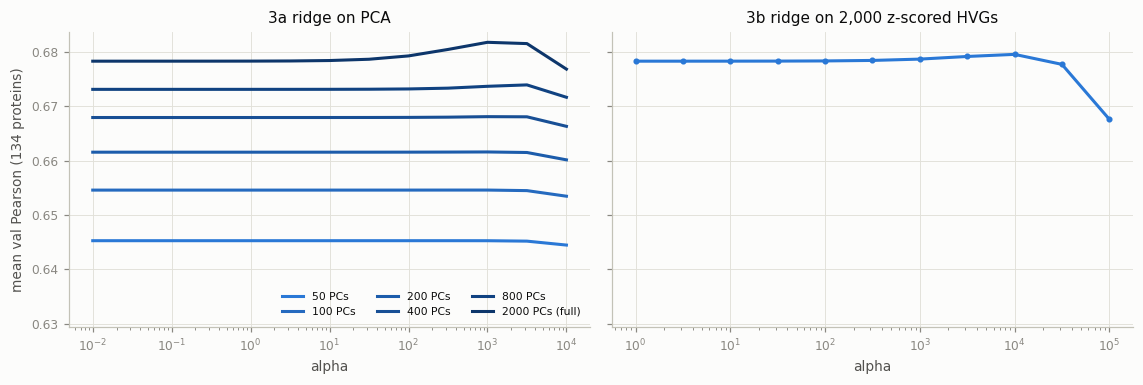

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
ax = axes[0]
ns = sorted(grid_pca["n_pcs"].unique())
ramp = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
for n, colr in zip(ns, ramp[-len(ns):]):
    g = grid_pca[grid_pca["n_pcs"] == n].sort_values("alpha")
    ax.plot(g["alpha"], g["val_mean_pearson"], color=colr, lw=2, label=f"{int(n)} PCs" + (" (full)" if n == N_HVG else ""))
ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("mean val Pearson (134 proteins)")
lo = grid["val_mean_pearson"].min()
ax.set_ylim(lo - 0.015, None)
ax.set_title("3a ridge on PCA"); ax.legend(frameon=False, fontsize=7, ncol=3, loc="lower right")
ax = axes[1]
g = grid[grid["model"] == "3b ridge HVG"].sort_values("alpha")
ax.plot(g["alpha"], g["val_mean_pearson"], color=P.BLUE, lw=2, marker="o", ms=3)
ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_title("3b ridge on 2,000 z-scored HVGs")
fig.tight_layout()
fig.savefig(OUT_FIG / "phase3_ridge_selection.png")

In [9]:
b = best.loc["3a ridge PCA"]
n_best, a_best = int(b["n_pcs"]), float(b["alpha"])
pred["3a ridge PCA"] = pca_paths[n_best].predict(Z_va[:, :n_best], a_best)
a_hvg = float(best.loc["3b ridge HVG", "alpha"])
pred["3b ridge HVG"] = rp_h.predict(H_va, a_hvg)
del rp_h, H_tr, H_va
print("3a:", n_best, "PCs, alpha", a_best, "| 3b: alpha", a_hvg)

3a: 2000 PCs, alpha 1000.0 | 3b: alpha 10000.0


### Sanity check: ridge on full-rank PCA = ridge on unscaled HVG

Full-rank PCA is an orthogonal rotation of the centered HVG matrix, and ridge does not change under such
rotations. So with the same preprocessing (log-normalized, centered, **not** z-scored) and the same alpha,
both must give the same predictions. Model 3b z-scores the HVGs first, so it is a different model and is
not part of this check.

In [10]:
U_tr, U_va = feats.hvg_dense(X_tr), feats.hvg_dense(X_va)
rp_u = RidgePath().fit(U_tr, Y_tr, [])
check = []
a_full = float(grid_pca.loc[grid_pca[grid_pca["n_pcs"] == N_HVG]["val_mean_pearson"].idxmax(), "alpha"])
for a in sorted({1.0, a_full}):
    rp_u.extend([a]); pca_paths[N_HVG].extend([a])
    p_u = rp_u.predict(U_va, a)
    p_z = pca_paths[N_HVG].predict(Z_va, a)
    check.append({"alpha": a, "max_abs_diff": float(np.abs(p_u - p_z).max()),
                  "max_abs_diff / protein SD": float((np.abs(p_u - p_z).max(axis=0) / Y_va.std(axis=0)).max()),
                  "val_mean_pearson_pca": sel_metric(p_z), "val_mean_pearson_hvg_unscaled": sel_metric(p_u)})
del rp_u, U_tr, U_va
check = pd.DataFrame(check)
check

,alpha,max_abs_diff,max_abs_diff / protein SD,val_mean_pearson_pca,val_mean_pearson_hvg_unscaled
0,1.000,0.000,0.000,0.678,0.678
1,1000.000,0.000,0.000,0.682,0.682


In [11]:
frozen = {
    "split_file": "results/splits/random_split.csv.gz", "seed": SEED,
    "features": {"hvg": N_HVG, "hvg_flavor": "seurat", "hvg_batch_key": "batch",
                 "pca_solver": "covariance_eigh", "pca_components": int(feats.pca_.n_components_)},
    "selection_metric": "mean validation Pearson over all 134 proteins",
    "grids": {"3a_n_pcs": [int(n) for n in sorted(grid_pca["n_pcs"].unique())],
              "3a_alphas_initial": ALPHA_PCA, "3b_alphas": sorted(float(a) for a in grid.loc[grid["model"] == "3b ridge HVG", "alpha"])},
    "grid_extensions_based_on_validation": expansion_log,
    "3a_ridge_pca": {"n_pcs": n_best, "alpha": a_best},
    "3b_ridge_hvg": {"alpha": a_hvg},
    "within_type_min_cells": MIN_CELLS_WITHIN,
    "n_cell_types_evaluable_random_split": evaluable,
    "sanity_full_rank_pca_vs_unscaled_hvg_max_abs_diff": float(check["max_abs_diff"].max()),
}
if SUBSET is None:
    (RESULTS_DIR / "phase3_frozen_configs.json").write_text(json.dumps(frozen, indent=2))
frozen

{'split_file': 'results/splits/random_split.csv.gz',
 'seed': 0,
 'features': {'hvg': 2000,
  'hvg_flavor': 'seurat',
  'hvg_batch_key': 'batch',
  'pca_solver': 'covariance_eigh',
  'pca_components': 2000},
 'selection_metric': 'mean validation Pearson over all 134 proteins',
 'grids': {'3a_n_pcs': [50, 100, 200, 400, 800, 2000],
  '3a_alphas_initial': [0.01,
   0.03162277660168379,
   0.1,
   0.31622776601683794,
   1.0,
   3.1622776601683795,
   10.0,
   31.622776601683793,
   100.0,
   316.22776601683796,
   1000.0,
   3162.2776601683795,
   10000.0],
  '3b_alphas': [1.0,
   3.1622776601683795,
   10.0,
   31.622776601683793,
   100.0,
   316.22776601683796,
   1000.0,
   3162.2776601683795,
   10000.0,
   31622.776601683792,
   100000.0]},
 'grid_extensions_based_on_validation': ['3a: best n_pcs is full rank (upper bound by construction, cannot be extended)'],
 '3a_ridge_pca': {'n_pcs': 2000, 'alpha': 1000.0},
 '3b_ridge_hvg': {'alpha': 10000.0},
 'within_type_min_cells': {'random

## 6. Validation results

In [12]:
per = {m: evaluate(Y_va, p, ct_va, proteins, MIN_CELLS) for m, p in pred.items()}
long = pd.concat({m: d.assign(analysis_set=SETS) for m, d in per.items()}, names=["model"]).reset_index()
if SUBSET is None:
    long.to_csv(RESULTS_DIR / "phase3_val_per_protein.csv", index=False)

def fmt(h, m):
    r = h.loc[m]
    if r["n_defined"] == 0:
        return "undefined"
    return f"{r['median']:.3f} [{r['q25']:.3f}-{r['q75']:.3f}]"

def table(prots):
    rows = {}
    for m, d in per.items():
        h = headline(d, prots)
        rows[m] = {"Pearson, all cells": fmt(h, "pearson_all"),
                   "within type, weighted": fmt(h, "within_w"),
                   "within type, unweighted": fmt(h, "within_unw"),
                   "RMSE": fmt(h, "rmse"),
                   "proteins with defined Pearson": f"{int(h.loc['pearson_all', 'n_defined'])}/{len(prots)}"}
    return pd.DataFrame(rows).T

n_types_val = pd.Series(ct_va).value_counts().ge(MIN_CELLS).sum()
print(f"PRIMARY set ({len(primary)} proteins), validation, median [IQR] across proteins; "
      f"within-type over {n_types_val} cell types with >= {MIN_CELLS} validation cells")
table(primary)

PRIMARY set (110 proteins), validation, median [IQR] across proteins; within-type over 34 cell types with >= 50 validation cells


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,"Pearson, all cells","within type, weighted","within type, unweighted",RMSE,proteins with defined Pearson
0 global mean,undefined,undefined,undefined,0.509 [0.353-0.691],0/110
1 cell-type mean (labels),0.647 [0.469-0.727],undefined,undefined,0.354 [0.296-0.470],110/110
2 own gene,0.286 [0.146-0.451],0.080 [0.041-0.126],0.097 [0.046-0.155],0.448 [0.333-0.645],110/110
3a ridge PCA,0.733 [0.577-0.826],0.337 [0.270-0.430],0.326 [0.246-0.420],0.312 [0.275-0.415],110/110
3b ridge HVG,0.731 [0.572-0.826],0.333 [0.262-0.422],0.318 [0.241-0.411],0.313 [0.276-0.416],110/110


In [13]:
print("SECONDARY set (separate)")
display(table(SETS.index[SETS == "secondary"].tolist()))
print("UNAVAILABLE set (no measured gene: own-gene model cannot predict them)")
table(SETS.index[SETS == "unavailable"].tolist())

SECONDARY set (separate)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,"Pearson, all cells","within type, weighted","within type, unweighted",RMSE,proteins with defined Pearson
0 global mean,undefined,undefined,undefined,0.695 [0.649-0.932],0/7
1 cell-type mean (labels),0.762 [0.733-0.796],undefined,undefined,0.452 [0.416-0.599],7/7
2 own gene,0.383 [0.153-0.482],0.101 [0.054-0.161],0.148 [0.054-0.157],0.642 [0.569-0.816],7/7
3a ridge PCA,0.856 [0.779-0.875],0.378 [0.332-0.429],0.358 [0.298-0.440],0.396 [0.357-0.455],7/7
3b ridge HVG,0.856 [0.778-0.875],0.369 [0.327-0.427],0.347 [0.297-0.432],0.398 [0.358-0.456],7/7


UNAVAILABLE set (no measured gene: own-gene model cannot predict them)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy

,"Pearson, all cells","within type, weighted","within type, unweighted",RMSE,proteins with defined Pearson
0 global mean,undefined,undefined,undefined,0.311 [0.256-0.442],0/17
1 cell-type mean (labels),0.393 [0.302-0.580],undefined,undefined,0.281 [0.243-0.344],17/17
2 own gene,undefined,undefined,undefined,undefined,0/17
3a ridge PCA,0.466 [0.388-0.619],0.247 [0.158-0.292],0.195 [0.148-0.277],0.271 [0.236-0.338],17/17
3b ridge HVG,0.466 [0.381-0.617],0.235 [0.149-0.279],0.183 [0.137-0.266],0.272 [0.236-0.339],17/17


In [14]:
# How often is a within-type r undefined for a model that should have one? (primary set)
for m in ["2 own gene", "3a ridge PCA", "3b ridge HVG"]:
    d = per[m].loc[primary]
    print(f"{m:<16} cell types used per protein: {int(d['n_types'].median())}, "
          f"proteins with >= 1 undefined type: {(d['n_types_nan'] > 0).sum()}, "
          f"undefined (protein, type) pairs: {int(d['n_types_nan'].sum())}")

2 own gene       cell types used per protein: 34, proteins with >= 1 undefined type: 87, undefined (protein, type) pairs: 774
3a ridge PCA     cell types used per protein: 34, proteins with >= 1 undefined type: 0, undefined (protein, type) pairs: 0
3b ridge HVG     cell types used per protein: 34, proteins with >= 1 undefined type: 0, undefined (protein, type) pairs: 0


## 7. What do multi-gene models add over the own gene and over cell-type identity?

In [15]:
best_ridge = max(["3a ridge PCA", "3b ridge HVG"], key=lambda m: best.loc[m, "val_mean_pearson"])
print("better ridge by the selection metric:", best_ridge)
own_p, rid_p, ctm_p = per["2 own gene"].loc[primary], per[best_ridge].loc[primary], per["1 cell-type mean (labels)"].loc[primary]
for metric in ["pearson_all", "within_w"]:
    d = rid_p[metric] - own_p[metric]
    print(f"{metric:<12} ridge - own gene: median {d.median():+.3f}; ridge better for {(d > 0).sum()} of {d.notna().sum()}")
d = rid_p["pearson_all"] - ctm_p["pearson_all"]
print(f"pearson_all  ridge - cell-type mean: median {d.median():+.3f}; ridge better for {(d > 0).sum()} of {d.notna().sum()}")

better ridge by the selection metric: 3a ridge PCA
pearson_all  ridge - own gene: median +0.394; ridge better for 110 of 110
within_w     ridge - own gene: median +0.256; ridge better for 110 of 110
pearson_all  ridge - cell-type mean: median +0.084; ridge better for 109 of 110


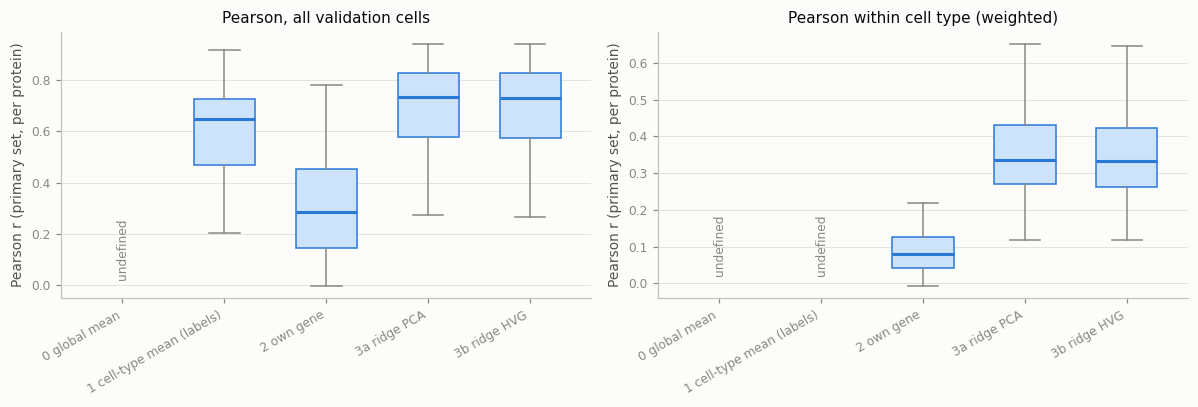

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
order = list(per)
for ax, metric, title in zip(axes, ["pearson_all", "within_w"], ["Pearson, all validation cells", "Pearson within cell type (weighted)"]):
    vals = [per[m].loc[primary, metric].to_numpy() for m in order]
    defined = [m for m, v in zip(order, vals) if np.isfinite(v).any()]
    data = [v[np.isfinite(v)] for v in vals if np.isfinite(v).any()]
    pos = [order.index(m) + 1 for m in defined]
    ax.boxplot(data, positions=pos, showfliers=False, widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=P.BLUE), medianprops=dict(color=P.BLUE, lw=2),
               whiskerprops=dict(color=P.MUTED), capprops=dict(color=P.MUTED))
    for m in order:
        if m not in defined:
            ax.text(order.index(m) + 1, 0.02, "undefined", ha="center", va="bottom", fontsize=8, color=P.MUTED, rotation=90)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=30, ha="right")
    ax.set_xlim(0.4, len(order) + 0.6)
    ax.set_title(title); ax.set_ylabel("Pearson r (primary set, per protein)")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase3_models_val.png")

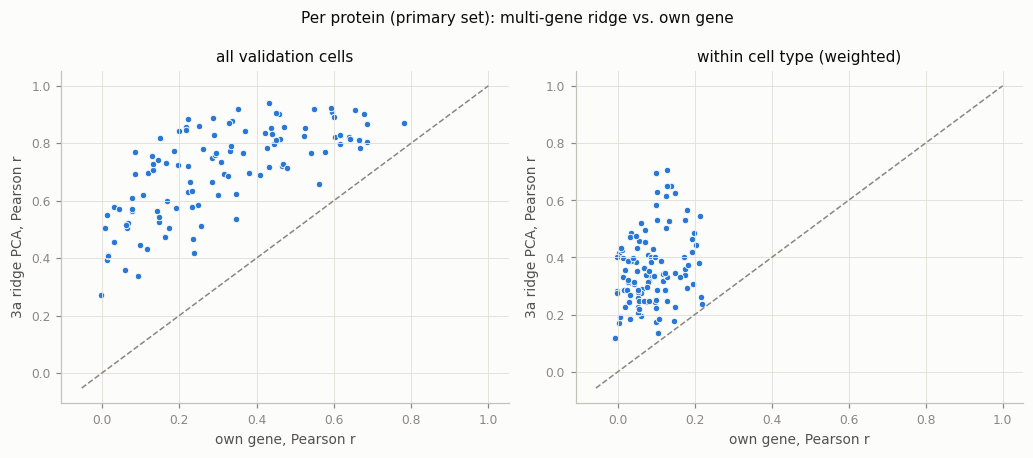

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, metric, title in zip(axes, ["pearson_all", "within_w"], ["all validation cells", "within cell type (weighted)"]):
    x, y = own_p[metric], rid_p[metric]
    lo = min(np.nanmin(x), np.nanmin(y), 0) - 0.05
    ax.plot([lo, 1], [lo, 1], color=P.MUTED, ls="--", lw=1)
    ax.scatter(x, y, s=18, c=P.BLUE, edgecolors=P.SURFACE, linewidths=0.6)
    ax.set_xlabel("own gene, Pearson r"); ax.set_ylabel(f"{best_ridge}, Pearson r")
    ax.set_title(title)
fig.suptitle("Per protein (primary set): multi-gene ridge vs. own gene", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase3_ridge_vs_own_gene.png")

In [18]:
if SUBSET is None:
    np.savez_compressed(PROCESSED_DIR / "phase3_val_predictions.npz", proteins=np.array(proteins),
                        y_val=Y_va.astype(np.float32), **{k.replace(" ", "_"): v.astype(np.float32) for k, v in pred.items()})
import resource, platform
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
print(f"peak memory: {(peak / 1e9 if platform.system() == 'Darwin' else peak * 1024 / 1e9):.2f} GB")

peak memory: 3.88 GB


## Findings (full data, **validation only**: test cells were not evaluated)

Primary set (110 proteins), 13,539 validation cells, 34 cell types with >= 50 validation cells
(the test part also has 34). Median [IQR] across proteins:

| Model | Pearson, all cells | within type (weighted) | RMSE |
|---|---|---|---|
| 0 global mean | undefined | undefined | 0.51 |
| 1 cell-type mean (**uses labels**) | 0.65 [0.47-0.73] | undefined | 0.35 |
| 2 own gene | 0.29 [0.15-0.45] | 0.08 [0.04-0.13] | 0.45 |
| 3a ridge, PCA (selected: full rank) | **0.73** [0.58-0.83] | **0.34** [0.27-0.43] | 0.31 |
| 3b ridge, z-scored HVG | 0.73 [0.57-0.83] | 0.33 [0.26-0.42] | 0.31 |

**Sanity checks**
* Own gene reproduces Phase 2 (0.29 overall, 0.08 within).
* Global-mean RMSE equals the protein standard deviation.
* Ridge on full-rank PCA equals ridge on the unscaled HVG matrix (max |difference| 2.4e-6).

**Grid.** More components were always better (mean validation Pearson 0.645 with 50 PCs up to 0.682
with 2,000). The best setting is full rank, the upper bound by construction (logged, cannot be extended).
So truncating with PCA did not help, and 3a is effectively ridge on unscaled HVGs. z-scoring (3b)
changes very little.

**What multi-gene RNA adds**
* Over the own gene: about +0.39 overall and +0.26 within type (median). Ridge is better for all
  110 proteins on both metrics.
* Over cell-type identity: ridge, which sees no labels, beats the label-based cell-type mean overall
  for 109 of 110 proteins (median +0.08). It also predicts within-type variation (0.34), which the
  cell-type mean cannot do at all.

**Caveats (hypotheses, not tested here)**
* "Within type" means within the 45 annotated labels. Part of the within-type signal may be finer
  structure inside a label (e.g. activation states).
* With a random split the same samples are in training and validation. Ridge could pick up
  sample/site signatures from RNA and use them to predict the site-dependent protein background, which
  would inflate within-type correlations. The donor split in Phase 5 is meant to test this.
* Validation numbers for ridge are slightly optimistic because its hyperparameters were chosen on
  these cells.

**Other sets.** The 17 proteins without a measured gene are predicted less well by ridge (0.47 overall,
0.25 within type), and the cell-type mean is also lower for them (0.39). This supports the concern that
they are a harder subset. Own-gene model: for 774 (protein, cell type) pairs the gene is not detected
in any validation cell of that type, so r is undefined there (counted, not set to 0). 7 primary
proteins have a negative own-gene slope.

Peak memory 3.9 GB, runtime ~1.5 min.